#**Aquora - Water Quality ML**
### pH + TDS + Turbidity + Temperature

This notebook tests different ML models for estimating `Water_Quality_Index`.

The main inputs are:
- pH
- TDS
- Turbidity
- Temperature


In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor

import xgboost as xgb
import lightgbm as lgb

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#**1- Load data**

In [3]:
DATA_PATH = "/content/drive/MyDrive/VIEW_2_ML_dataset_WITH_SCADA_CONTEXT_FINAL.csv"

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
df.head(3)

Shape: (100000, 80)


,Asset_ID,Asset_Type,Pipe_Material,Pipe_Diameter_cm,Pipe_Length_m,Pipe_Depth_m,Frost_Depth_m,Installation_Year,Installation_Date,Pipe_Age_Years,Condition_Score,Criticality,Criticality_Score,Lined,Undersized,Shallow_Main,Oversized,Cleaned,Pressure_Sensor_ID,Pressure,Pressure_Unit,Flow_Sensor_ID,Flow_Rate,Flow_Unit,Pressure_Deviation,Flow_Deviation,Pressure_Change_Rate,Flow_Change_Rate,Pressure_Flow_Ratio,Temperature_C,pH,TDS_mg_L,Turbidity_NTU,Dissolved_Oxygen_mg_L,Conductivity_umhos_cm,BOD_mg_L,Nitrate_Nitrite_mg_L,Fecal_Coliform_MPN_100ml,Total_Coliform_MPN_100ml,Timestamp,Observation_Date,Year,Month,Day,Hour,Day_of_Week,Season,Previous_Failures,Failures_Last_1_Year,Failures_Last_3_Years,Failures_Last_5_Years,Days_Since_Last_Failure,Vibration_RMS,Vibration_STD,Vibration_Min,Vibration_Max,Vibration_PeakToPeak,Vibration_Energy,Vibration_Kurtosis,Vibration_Skewness,Acoustic_RMS,Acoustic_STD,Acoustic_Min,Acoustic_Max,Acoustic_PeakToPeak,Acoustic_Energy,Acoustic_Kurtosis,Acoustic_Skewness,Sensor_Anomaly_Score,Water_Quality_Index,Asset_Risk_Score,Failure_Next_7_Days,Failure_Next_30_Days,Failure_Next_90_Days,Leak_No_Leak,Leak_Type,Leak_Type_Eligible,Days_Since_Last_Failure_Was_Missing,Water_Demand,Tank_Level
0,AST_0001,MAIN,PVC,75,79.756031,0.998648,0.683814,1982,1982-10-21,41.20,64.953862,Medium,0.5,False,False,False,False,True,PS_01,492.942796,kPa,FS_01,23.721263,L/s,5.246460,-0.526828,0.000000,0.000000,20.780630,15.219513,7.016111,300.375051,2.000794,7.380540,467.082677,2.023401,1.700806,16.847856,216.049319,2024-01-01 13:00:00,2024-01-01,2024,1,1,13,Monday,Winter,0,0,0,0,0.0,1.055900,0.506388,0.619898,1.868553,1.248655,1.263649,3.305895,-0.048920,1.136093,0.117225,0.972840,1.467445,0.494605,1.392091,4.213682,0.072320,0.068997,93.911859,0.456663,0,0,1,0,No Leak,0,1,17.6024,3.4759
1,AST_0001,MAIN,PVC,75,79.756031,0.998648,0.683814,1982,1982-10-21,41.23,64.953862,Medium,0.5,False,False,False,False,True,PS_01,488.936767,kPa,FS_01,19.153524,L/s,1.240430,-5.094567,-4.006030,-4.567739,25.527249,13.558305,7.417775,335.229932,2.205246,8.402581,529.458958,2.408435,0.264011,7.868098,14.867438,2024-01-12 15:00:00,2024-01-12,2024,1,12,15,Friday,Winter,0,0,0,0,0.0,0.866672,0.426057,0.333862,1.614264,1.280402,0.528015,3.106466,0.554489,0.969437,0.390504,0.520110,1.524734,1.004624,0.696380,3.996373,0.546372,0.264276,95.073807,0.514806,0,0,1,0,No Leak,0,1,15.2788,3.4800
2,AST_0001,MAIN,PVC,75,79.756031,0.998648,0.683814,1982,1982-10-21,41.27,64.953862,Medium,0.5,False,False,False,False,True,PS_01,473.428790,kPa,FS_01,28.302695,L/s,-14.267547,4.054604,-15.507977,9.149171,16.727340,16.654881,7.721253,274.119095,2.634215,7.762196,451.049528,2.208926,1.613031,5.891604,90.786107,2024-01-26 07:00:00,2024-01-26,2024,1,26,7,Friday,Winter,0,0,0,0,0.0,0.756531,0.648730,0.354854,1.693104,1.338250,0.621291,2.703215,0.297994,1.094916,0.223058,0.928289,1.179522,0.251233,1.301118,3.799924,0.156802,0.364087,90.911979,0.487931,0,0,1,0,No Leak,0,1,23.5261,3.4689


#**Data quality check**

In [4]:
print("Missing values total:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Columns:", df.shape[1])

print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False).head(10))

print("\nObject columns:")
for c in df.select_dtypes(include="object").columns:
    print(c, "->", df[c].nunique(), "unique")

Missing values total: 0
Duplicate rows: 0
Columns: 80

Missing values:
Asset_ID             0
Asset_Type           0
Pipe_Material        0
Pipe_Diameter_cm     0
Pipe_Length_m        0
Pipe_Depth_m         0
Frost_Depth_m        0
Installation_Year    0
Installation_Date    0
Pipe_Age_Years       0
dtype: int64

Object columns:
Asset_ID -> 1250 unique
Asset_Type -> 2 unique
Pipe_Material -> 5 unique
Installation_Date -> 1211 unique
Criticality -> 4 unique
Pressure_Sensor_ID -> 33 unique
Pressure_Unit -> 1 unique
Flow_Sensor_ID -> 45 unique
Flow_Unit -> 1 unique
Timestamp -> 9504 unique
Observation_Date -> 396 unique
Day_of_Week -> 7 unique
Season -> 4 unique
Leak_Type -> 5 unique


#**2- Water quality columns**

In [5]:
water_cols = [
    c for c in [
        "pH",
        "Turbidity_NTU",
        "TDS_mg_L",
        "Temperature_C",
        "Conductivity_umhos_cm",
        "Dissolved_Oxygen_mg_L",
        "BOD_mg_L",
        "Nitrate_Nitrite_mg_L",
        "Fecal_Coliform_MPN_100ml",
        "Total_Coliform_MPN_100ml",
        "Water_Quality_Index"
    ] if c in df.columns
]

print(water_cols)

print("\nSummary:")
display(df[water_cols].describe().T)

['pH', 'Turbidity_NTU', 'TDS_mg_L', 'Temperature_C', 'Conductivity_umhos_cm', 'Dissolved_Oxygen_mg_L', 'BOD_mg_L', 'Nitrate_Nitrite_mg_L', 'Fecal_Coliform_MPN_100ml', 'Total_Coliform_MPN_100ml', 'Water_Quality_Index']

Summary:


,count,mean,std,min,25%,50%,75%,max
pH,100000.0,7.334529,0.351515,5.800000,7.095521,7.334116,7.572119,8.941768
Turbidity_NTU,100000.0,2.584441,0.535134,0.553605,2.210548,2.530157,2.909023,5.782912
TDS_mg_L,100000.0,281.164611,59.576023,83.609516,238.476475,278.569921,321.250505,599.336580
Temperature_C,100000.0,15.357366,7.338248,1.000000,8.608985,15.677795,21.956139,32.382039
Conductivity_umhos_cm,100000.0,439.395872,79.022853,131.728157,382.634156,439.954723,496.365021,739.056415
Dissolved_Oxygen_mg_L,100000.0,8.220341,0.991287,4.854387,7.434793,8.196181,9.004806,11.514073
BOD_mg_L,100000.0,2.359949,0.276658,1.754210,2.159315,2.307301,2.521903,6.137016
Nitrate_Nitrite_mg_L,100000.0,2.086228,0.848064,0.010000,1.506635,2.084746,2.661338,5.880579
Fecal_Coliform_MPN_100ml,100000.0,27.704035,24.257660,1.000000,12.499021,20.881700,34.657280,508.735044
Total_Coliform_MPN_100ml,100000.0,160.881331,129.729814,7.560693,77.688868,124.973483,201.730676,3960.346472


#**3- Target check**

In [6]:
for c in ["Water_Quality_Index", "Leak_No_Leak", "Leak_Type", "Leak_Type_Eligible"]:
    if c in df.columns:
        print("\n", c)
        print(df[c].value_counts(dropna=False).head(10))


 Water_Quality_Index
Water_Quality_Index
100.000000    14072
83.654442         1
96.733361         1
99.931827         1
91.162047         1
85.224308         1
98.390348         1
92.326311         1
99.971822         1
87.575924         1
Name: count, dtype: int64

 Leak_No_Leak
Leak_No_Leak
0    89175
1    10825
Name: count, dtype: int64

 Leak_Type
Leak_Type
No Leak                  89175
Circumferential Crack     3128
Gasket Leak               2982
Longitudinal Crack        2918
Orifice Leak              1797
Name: count, dtype: int64

 Leak_Type_Eligible
Leak_Type_Eligible
0    89175
1    10825
Name: count, dtype: int64


**Finding**

For this water-quality experiment we use `Water_Quality_Index` as the target.

`Leak_No_Leak` is a leak label, so it is not used as the water-quality target.

There is no separate verified Safe/Unsafe contamination target in this dataset, so we do not create one ourselves.

#**4- WQI note**

In [7]:
print(df["Water_Quality_Index"].describe())

print("\nUnique WQI values:", df["Water_Quality_Index"].nunique())
print("Min:", df["Water_Quality_Index"].min())
print("Max:", df["Water_Quality_Index"].max())

count    100000.000000
mean         93.722751
std           4.786073
min          73.299176
25%          90.318941
50%          94.073191
75%          97.853912
max         100.000000
Name: Water_Quality_Index, dtype: float64

Unique WQI values: 85929
Min: 73.29917604919756
Max: 100.0


WQI may be calculated from some of the same water-quality measurements used as inputs.

So this experiment shows how well the sensors can estimate the existing WQI. It should not be described as proof of independent contamination detection.

#**5- Range check**

In [8]:
checks = {}

limits = {
    "pH": (0, 14),
    "Turbidity_NTU": (0, np.inf),
    "TDS_mg_L": (0, np.inf),
    "Temperature_C": (-50, 100),
    "Conductivity_umhos_cm": (0, np.inf),
    "Dissolved_Oxygen_mg_L": (0, np.inf),
    "BOD_mg_L": (0, np.inf),
    "Nitrate_Nitrite_mg_L": (0, np.inf)
}

for c, (lo, hi) in limits.items():
    if c in df.columns:
        bad = ((df[c] < lo) | (df[c] > hi)).sum()
        checks[c] = int(bad)

print(pd.Series(checks, name="invalid_values"))

pH                       0
Turbidity_NTU            0
TDS_mg_L                 0
Temperature_C            0
Conductivity_umhos_cm    0
Dissolved_Oxygen_mg_L    0
BOD_mg_L                 0
Nitrate_Nitrite_mg_L     0
Name: invalid_values, dtype: int64


#**6- Distributions**

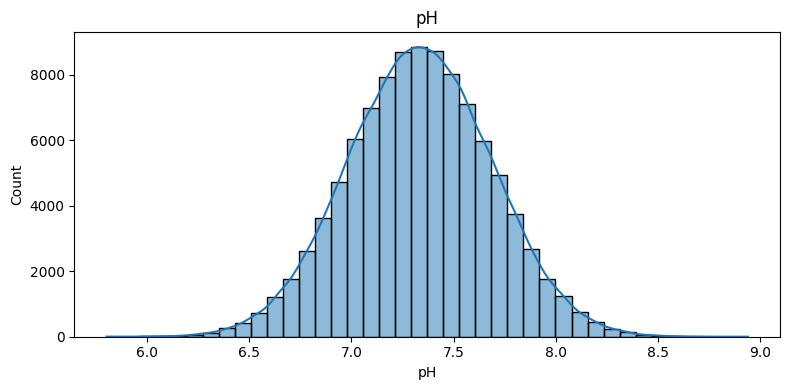

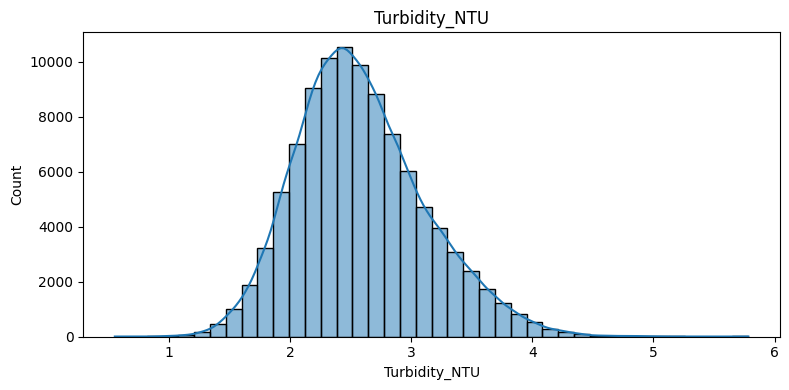

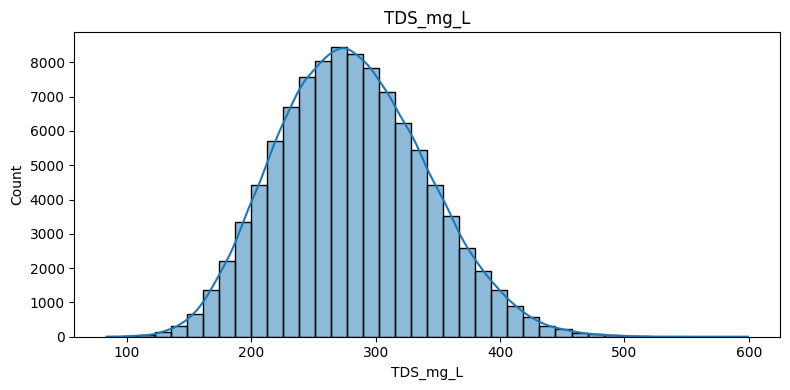

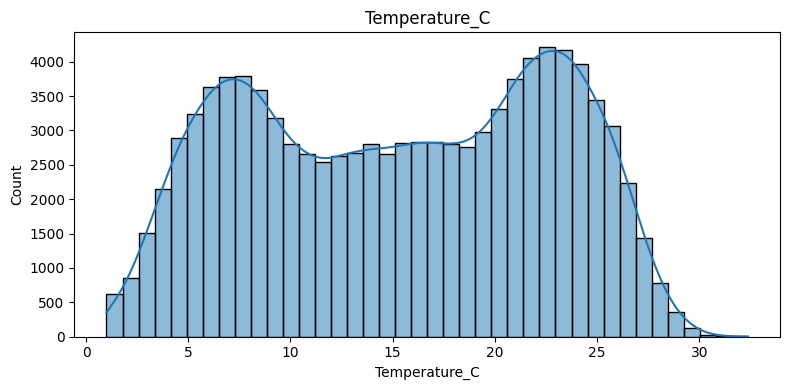

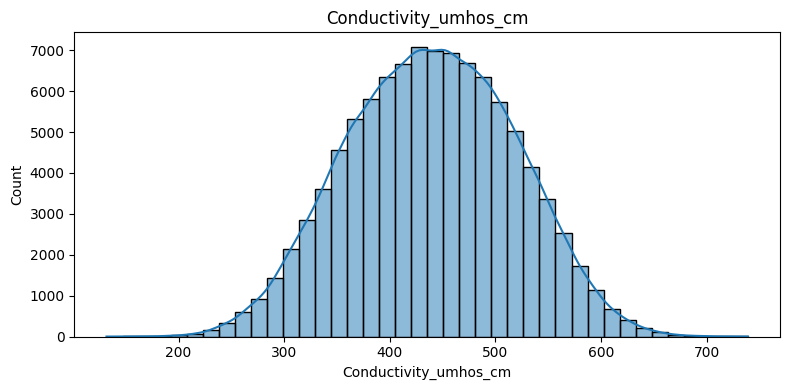

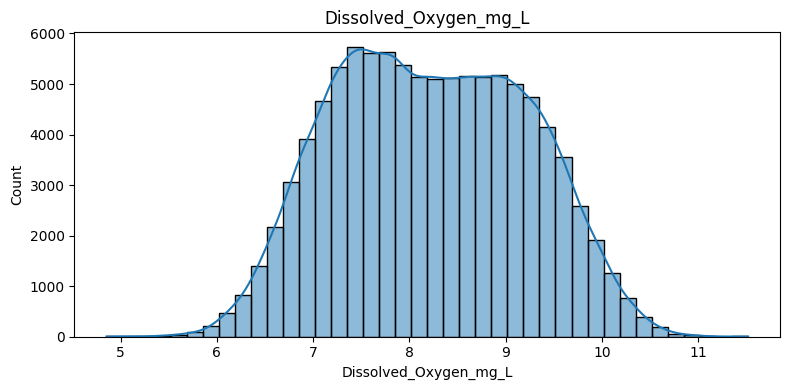

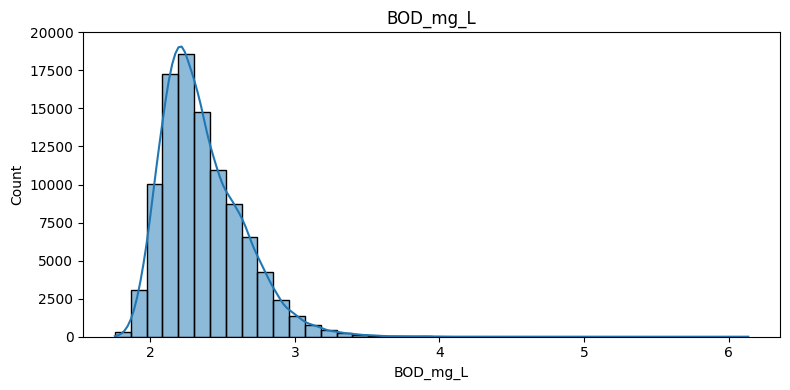

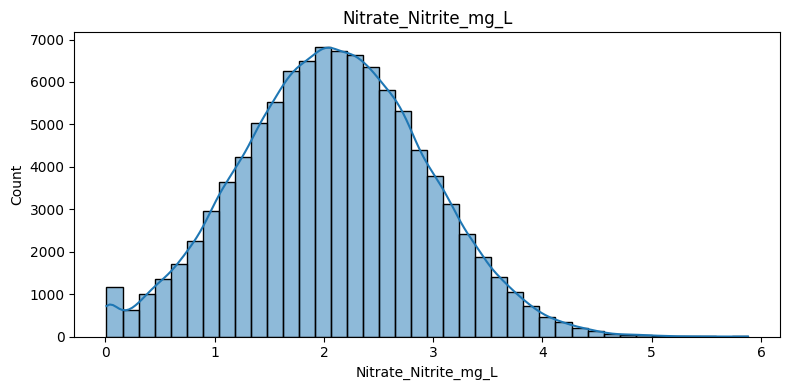

In [9]:
plot_cols = [c for c in [
    "pH", "Turbidity_NTU", "TDS_mg_L", "Temperature_C",
    "Conductivity_umhos_cm", "Dissolved_Oxygen_mg_L",
    "BOD_mg_L", "Nitrate_Nitrite_mg_L"
] if c in df.columns]

for c in plot_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[c], bins=40, kde=True)
    plt.title(c)
    plt.tight_layout()
    plt.show()

#**7- Correlation**

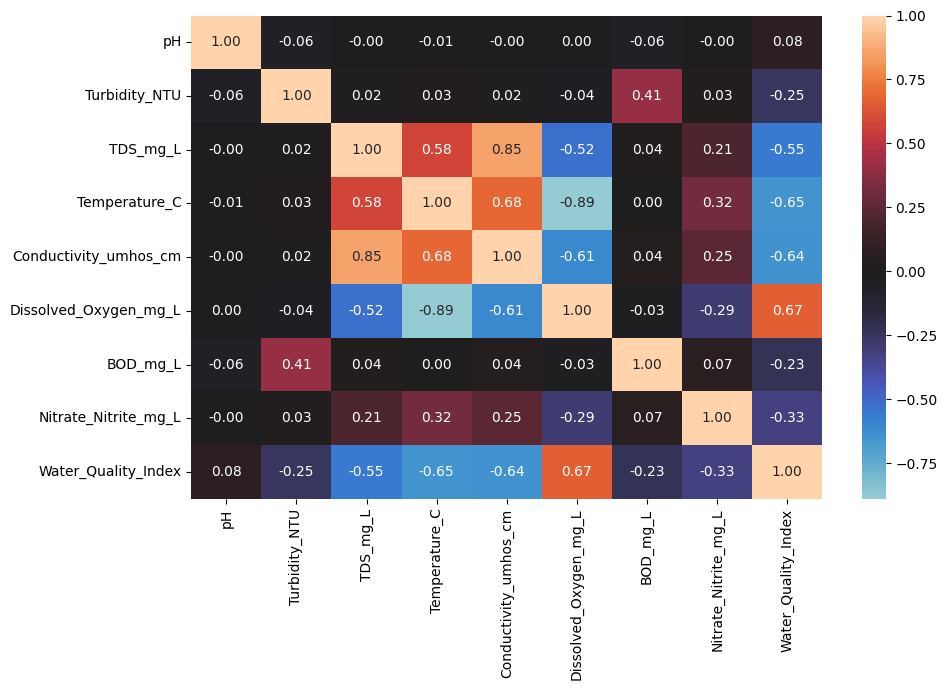

In [10]:
corr_cols = [c for c in [
    "pH", "Turbidity_NTU", "TDS_mg_L", "Temperature_C",
    "Conductivity_umhos_cm", "Dissolved_Oxygen_mg_L",
    "BOD_mg_L", "Nitrate_Nitrite_mg_L", "Water_Quality_Index"
] if c in df.columns]

plt.figure(figsize=(10, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", center=0)
plt.tight_layout()
plt.show()

#**8- Group split**

In [11]:
TARGET = "Water_Quality_Index"
GROUP = "Asset_ID"

features = [
    c for c in [
        "pH",
        "Turbidity_NTU",
        "TDS_mg_L",
        "Temperature_C"
    ] if c in df.columns
]

print("Features:", features)
print("Target:", TARGET)
print("Groups:", GROUP)

print("\nNumber of assets:", df[GROUP].nunique())
print("Rows per asset:")
print(df.groupby(GROUP).size().describe())

Features: ['pH', 'Turbidity_NTU', 'TDS_mg_L', 'Temperature_C']
Target: Water_Quality_Index
Groups: Asset_ID

Number of assets: 1250
Rows per asset:
count    1250.0
mean       80.0
std         0.0
min        80.0
25%        80.0
50%        80.0
75%        80.0
max        80.0
dtype: float64


In [12]:
# 60 / 20 / 20 by Asset_ID

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
trainval_idx, test_idx = next(gss1.split(df, df[TARGET], groups=df[GROUP]))

trainval = df.iloc[trainval_idx].copy()
test = df.iloc[test_idx].copy()

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
train_idx, val_idx = next(gss2.split(trainval, trainval[TARGET], groups=trainval[GROUP]))

train = trainval.iloc[train_idx].copy()
val = trainval.iloc[val_idx].copy()

print("Train:", train.shape)
print("Validation:", val.shape)
print("Test:", test.shape)

print("\nAsset overlap:")
print("train / val:", len(set(train[GROUP]) & set(val[GROUP])))
print("train / test:", len(set(train[GROUP]) & set(test[GROUP])))
print("val / test:", len(set(val[GROUP]) & set(test[GROUP])))

Train: (60000, 80)
Validation: (20000, 80)
Test: (20000, 80)

Asset overlap:
train / val: 0
train / test: 0
val / test: 0


#**9- Feature engineering**

In [13]:
def add_features(data):
    x = data[features].copy()

    if "pH" in x.columns and "Temperature_C" in x.columns:
        x["pH_Temperature"] = x["pH"] * x["Temperature_C"]

    if "TDS_mg_L" in x.columns and "Turbidity_NTU" in x.columns:
        x["TDS_Turbidity"] = x["TDS_mg_L"] * x["Turbidity_NTU"]

    return x

X_train = add_features(train)
X_val = add_features(val)
X_test = add_features(test)

y_train = train[TARGET]
y_val = val[TARGET]
y_test = test[TARGET]

print("Features used:")
print(X_train.columns.tolist())
print("\nTrain shape:", X_train.shape)

Features used:
['pH', 'Turbidity_NTU', 'TDS_mg_L', 'Temperature_C', 'pH_Temperature', 'TDS_Turbidity']

Train shape: (60000, 6)


#**10- Models**

In [14]:
# Regression models used for CV comparison.
# Settings are chosen to keep 5-fold Group CV practical on the 100k-row dataset.
models = {
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Ridge": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=RANDOM_STATE))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=100, max_depth=12, min_samples_leaf=5, n_jobs=1, random_state=RANDOM_STATE
        ))
    ]),

    "Extra Trees": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", ExtraTreesRegressor(
            n_estimators=100, max_depth=12, min_samples_leaf=5, n_jobs=1, random_state=RANDOM_STATE
        ))
    ]),

    "HistGradientBoosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingRegressor(
            max_iter=100, learning_rate=0.08, max_leaf_nodes=31, l2_regularization=0.5, random_state=RANDOM_STATE
        ))
    ]),

    "XGBoost": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", xgb.XGBRegressor(
            n_estimators=100, max_depth=6, learning_rate=0.08, subsample=0.9, colsample_bytree=0.9,
            objective="reg:squarederror", eval_metric="rmse", n_jobs=1, tree_method="hist", random_state=RANDOM_STATE
        ))
    ]),

    "LightGBM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", lgb.LGBMRegressor(
            n_estimators=100, learning_rate=0.08, num_leaves=31, max_depth=-1,
            subsample=0.9, colsample_bytree=0.9, verbosity=-1, random_state=RANDOM_STATE, n_jobs=1
        ))
    ]),

    # RBF-SVR is O(n^2)-ish in memory/time. It is evaluated on a capped
    # training subset per fold, while its score is always computed on the full validation fold.
    "SVR": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVR(C=10, epsilon=0.1, kernel="rbf", cache_size=1000))
    ]),

    "ANN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", MLPRegressor(
            hidden_layer_sizes=(64, 32), activation="relu", solver="adam", alpha=0.0005,
            learning_rate_init=0.001, max_iter=150, early_stopping=True, validation_fraction=0.15,
            batch_size=256, random_state=RANDOM_STATE
        ))
    ])
}

print("Models:", list(models.keys()))

Models: ['Linear Regression', 'Ridge', 'Decision Tree', 'Random Forest', 'Extra Trees', 'HistGradientBoosting', 'XGBoost', 'LightGBM', 'SVR', 'ANN']


#**11- WQI reference check**

WQI is an index, not one universal formula.

A commonly used **NSF-WQI** is based on nine parameters:
- dissolved oxygen
- fecal coliform
- pH
- BOD
- nitrate
- phosphate
- temperature
- turbidity
- total solids

The index combines parameter-specific quality scores with weights. Our dataset has several related variables, but it does **not** exactly match the standard nine-parameter NSF set: phosphate and total solids are not present, while TDS and total coliform are present.

So we should **not assume that `Water_Quality_Index` in this dataset is the NSF-WQI**.

Current status:
- The dataset gives us the WQI values.
- The exact generation formula/source of those values is not documented in the notebook.
- Therefore the model experiment is currently an estimation of the dataset's existing WQI.
- The source of the dataset/WQI formula should be verified before interpreting the score as a standard drinking-water quality index.

References:
- U.S. EPA documentation on NSF-WQI: https://nepis.epa.gov/Exe/ZyPURL.cgi?Dockey=94005DMG.TXT
- Review of NSF-WQI: https://pmc.ncbi.nlm.nih.gov/articles/PMC10006569/
- WHO Guidelines for Drinking-water Quality (current edition): https://www.who.int/publications/i/item/9789240121225

WHO provides drinking-water guideline values and risk-management guidance; it does not define the NSF-WQI formula.

#**12- Feature sets**

We compare only water-quality information.

The main question is whether the four sensors already selected for Aquora are enough, or whether the other water-quality measurements in the dataset add a meaningful improvement.

The four-sensor setup is always kept as the baseline.

In [15]:
base_features = [
    c for c in ["pH", "Turbidity_NTU", "TDS_mg_L", "Temperature_C"]
    if c in df.columns
]

extra_water_quality = [
    c for c in [
        "Dissolved_Oxygen_mg_L",
        "Conductivity_umhos_cm",
        "BOD_mg_L",
        "Nitrate_Nitrite_mg_L",
        "Fecal_Coliform_MPN_100ml",
        "Total_Coliform_MPN_100ml"
    ] if c in df.columns
]

feature_sets = {
    "4 sensors": base_features,

    "4 + interactions": base_features.copy(),

    "4 + DO": base_features + [c for c in ["Dissolved_Oxygen_mg_L"] if c in df.columns],

    "4 + Conductivity": base_features + [c for c in ["Conductivity_umhos_cm"] if c in df.columns],

    "4 + BOD": base_features + [c for c in ["BOD_mg_L"] if c in df.columns],

    "4 + Nitrate": base_features + [c for c in ["Nitrate_Nitrite_mg_L"] if c in df.columns],

    "4 + Fecal Coliform": base_features + [c for c in ["Fecal_Coliform_MPN_100ml"] if c in df.columns],

    "4 + Total Coliform": base_features + [c for c in ["Total_Coliform_MPN_100ml"] if c in df.columns],

    "All water quality": base_features + extra_water_quality,
}

for name, cols in feature_sets.items():
    print(name, "->", cols)

4 sensors -> ['pH', 'Turbidity_NTU', 'TDS_mg_L', 'Temperature_C']
4 + interactions -> ['pH', 'Turbidity_NTU', 'TDS_mg_L', 'Temperature_C']
4 + DO -> ['pH', 'Turbidity_NTU', 'TDS_mg_L', 'Temperature_C', 'Dissolved_Oxygen_mg_L']
4 + Conductivity -> ['pH', 'Turbidity_NTU', 'TDS_mg_L', 'Temperature_C', 'Conductivity_umhos_cm']
4 + BOD -> ['pH', 'Turbidity_NTU', 'TDS_mg_L', 'Temperature_C', 'BOD_mg_L']
4 + Nitrate -> ['pH', 'Turbidity_NTU', 'TDS_mg_L', 'Temperature_C', 'Nitrate_Nitrite_mg_L']
4 + Fecal Coliform -> ['pH', 'Turbidity_NTU', 'TDS_mg_L', 'Temperature_C', 'Fecal_Coliform_MPN_100ml']
4 + Total Coliform -> ['pH', 'Turbidity_NTU', 'TDS_mg_L', 'Temperature_C', 'Total_Coliform_MPN_100ml']
All water quality -> ['pH', 'Turbidity_NTU', 'TDS_mg_L', 'Temperature_C', 'Dissolved_Oxygen_mg_L', 'Conductivity_umhos_cm', 'BOD_mg_L', 'Nitrate_Nitrite_mg_L', 'Fecal_Coliform_MPN_100ml', 'Total_Coliform_MPN_100ml']


In [16]:
# Create the engineered interaction columns once.
def make_feature_table(data, selected_features, include_interactions=False):
    x = data[selected_features].copy()

    if include_interactions:
        if "pH" in x.columns and "Temperature_C" in x.columns:
            x["pH_Temperature"] = x["pH"] * x["Temperature_C"]

        if "TDS_mg_L" in x.columns and "Turbidity_NTU" in x.columns:
            x["TDS_Turbidity"] = x["TDS_mg_L"] * x["Turbidity_NTU"]

    return x

print("Feature sets ready.")

Feature sets ready.


#**13- Five-fold Group CV**

In [17]:
# Model/feature selection is based on 5-fold Group CV only.
# The final test set is not used here.

gkf = GroupKFold(n_splits=5)
cv_splits = list(gkf.split(train, train[TARGET], groups=train[GROUP]))

# Fast feature screening with three strong nonlinear models.
screen_models = {
    "HistGradientBoosting": models["HistGradientBoosting"],
    "XGBoost": models["XGBoost"],
    "LightGBM": models["LightGBM"]
}

def grouped_cv_scores(model, X, y, groups, splits, model_name="", svr_cap=6000):
    """Manual 5-fold Group CV so progress is printed after every fold/model."""
    fold_rows = []
    for fold_no, (tr_idx, va_idx) in enumerate(splits, start=1):
        X_tr = X.iloc[tr_idx].copy()
        y_tr = y.iloc[tr_idx].copy()
        X_va = X.iloc[va_idx].copy()
        y_va = y.iloc[va_idx].copy()

        fit_model = clone(model)

        if model_name == "SVR" and len(X_tr) > svr_cap:
            # Deterministic subset; validation remains the complete fold.
            rng = np.random.RandomState(RANDOM_STATE + fold_no)
            keep = rng.choice(len(X_tr), size=svr_cap, replace=False)
            X_tr = X_tr.iloc[keep]
            y_tr = y_tr.iloc[keep]

        fit_model.fit(X_tr, y_tr)
        pred = fit_model.predict(X_va)

        fold_rows.append({
            "MAE": mean_absolute_error(y_va, pred),
            "RMSE": np.sqrt(mean_squared_error(y_va, pred)),
            "R2": r2_score(y_va, pred)
        })

    fold_df = pd.DataFrame(fold_rows)
    return {
        "CV_MAE": fold_df["MAE"].mean(),
        "CV_RMSE": fold_df["RMSE"].mean(),
        "CV_R2": fold_df["R2"].mean(),
        "CV_R2_STD": fold_df["R2"].std()
    }

screen_rows = []
start_time = time.time()

for feature_name, selected in feature_sets.items():
    use_interactions = feature_name == "4 + interactions"
    X_screen = make_feature_table(train, selected, include_interactions=use_interactions)
    y_screen = train[TARGET]

    for model_name, model in screen_models.items():
        t0 = time.time()
        result = grouped_cv_scores(model, X_screen, y_screen, train[GROUP], cv_splits, model_name=model_name)
        screen_rows.append({"Feature_Set": feature_name, "Model": model_name, **result})
        print(f"Done: {feature_name} | {model_name} | {time.time()-t0:.1f}s | CV R2={result['CV_R2']:.4f}")

feature_screen_df = pd.DataFrame(screen_rows).sort_values(
    ["CV_R2", "CV_RMSE"], ascending=[False, True]
).reset_index(drop=True)

print(f"Feature screening completed in {(time.time()-start_time)/60:.1f} minutes.")
display(feature_screen_df)

Done: 4 sensors | HistGradientBoosting | 3.6s | CV R2=0.5798
Done: 4 sensors | XGBoost | 2.5s | CV R2=0.5800
Done: 4 sensors | LightGBM | 2.3s | CV R2=0.5801
Done: 4 + interactions | HistGradientBoosting | 3.6s | CV R2=0.5810
Done: 4 + interactions | XGBoost | 4.4s | CV R2=0.5799
Done: 4 + interactions | LightGBM | 2.4s | CV R2=0.5814
Done: 4 + DO | HistGradientBoosting | 3.3s | CV R2=0.6193
Done: 4 + DO | XGBoost | 2.7s | CV R2=0.6193
Done: 4 + DO | LightGBM | 2.9s | CV R2=0.6194
Done: 4 + Conductivity | HistGradientBoosting | 4.4s | CV R2=0.6132
Done: 4 + Conductivity | XGBoost | 2.7s | CV R2=0.6136
Done: 4 + Conductivity | LightGBM | 2.4s | CV R2=0.6134
Done: 4 + BOD | HistGradientBoosting | 3.4s | CV R2=0.5946
Done: 4 + BOD | XGBoost | 5.6s | CV R2=0.5949
Done: 4 + BOD | LightGBM | 2.8s | CV R2=0.5949
Done: 4 + Nitrate | HistGradientBoosting | 3.5s | CV R2=0.5925
Done: 4 + Nitrate | XGBoost | 2.6s | CV R2=0.5930
Done: 4 + Nitrate | LightGBM | 3.0s | CV R2=0.5936
Done: 4 + Fecal Col

,Feature_Set,Model,CV_MAE,CV_RMSE,CV_R2,CV_R2_STD
0,All water quality,LightGBM,2.155915,2.740971,0.673144,0.002926
1,All water quality,XGBoost,2.156775,2.741866,0.672931,0.002823
2,All water quality,HistGradientBoosting,2.158549,2.744107,0.672393,0.003342
3,4 + DO,LightGBM,2.334727,2.957774,0.619398,0.003303
4,4 + DO,XGBoost,2.334022,2.958254,0.619275,0.003592
5,4 + DO,HistGradientBoosting,2.336019,2.958319,0.619258,0.003230
6,4 + Conductivity,XGBoost,2.355504,2.980235,0.613587,0.003747
7,4 + Conductivity,LightGBM,2.357955,2.981065,0.613372,0.003412
8,4 + Conductivity,HistGradientBoosting,2.359398,2.981922,0.613151,0.003062
9,4 + BOD,XGBoost,2.411429,3.051371,0.594917,0.005741


#**14- Does the 4-sensor setup lose much?**

#**15- Five-fold CV for the practical 4-sensor model**

The feature-screening experiment above studies whether additional water-quality parameters improve WQI estimation.
For the actual Aquora implementation, the final model must use only the four sensors that are currently available: pH, TDS, Turbidity, and Temperature.

Therefore, all 10 candidate regression models are compared on the four-sensor feature set using 5-fold Group CV. The test set remains untouched until final evaluation.


In [ ]:
# Model selection for the practical Aquora system uses ONLY the 4 available sensors.
# The test set remains untouched until final evaluation.
#
# The broader feature-screening experiment above is retained to answer the
# supervisor's question about whether additional water-quality parameters are useful.

feature_summary = (
    feature_screen_df
    .groupby("Feature_Set", as_index=False)
    .agg(
        Mean_CV_R2=("CV_R2", "mean"),
        Best_CV_R2=("CV_R2", "max"),
        Mean_CV_RMSE=("CV_RMSE", "mean"),
        Mean_CV_MAE=("CV_MAE", "mean")
    )
    .sort_values(["Mean_CV_R2", "Mean_CV_RMSE"], ascending=[False, True])
    .reset_index(drop=True)
)

# Research benchmark: strongest feature set found from 5-fold Group CV screening.
research_best_feature_set = feature_summary.iloc[0]["Feature_Set"]
research_best_cv_r2 = float(feature_summary.iloc[0]["Mean_CV_R2"])

print("Best research feature set from 5-fold CV screening:", research_best_feature_set)
display(feature_summary)

# Practical model-selection feature set: ONLY the four sensors physically available.
practical_feature_set = "4 sensors"
practical_features = feature_sets[practical_feature_set]
X_cv_practical = make_feature_table(train, practical_features, include_interactions=False)
y_cv_practical = train[TARGET]

print("\nPractical feature set used for final Aquora model selection:")
print(practical_features)

practical_cv_rows = []
start_time = time.time()

for model_name, model in models.items():
    t0 = time.time()
    result = grouped_cv_scores(
        model,
        X_cv_practical,
        y_cv_practical,
        train[GROUP],
        cv_splits,
        model_name=model_name,
        svr_cap=6000
    )
    practical_cv_rows.append({
        "Feature_Set": practical_feature_set,
        "Model": model_name,
        **result
    })
    print(f"Done: {model_name} | {time.time()-t0:.1f}s | CV R2={result['CV_R2']:.4f} | CV RMSE={result['CV_RMSE']:.4f}")

practical_cv_df = pd.DataFrame(practical_cv_rows).sort_values(
    ["CV_R2", "CV_RMSE", "CV_MAE"], ascending=[False, True, True]
).reset_index(drop=True)

print(f"\n4-sensor all-model 5-fold CV completed in {(time.time()-start_time)/60:.1f} minutes.")
display(practical_cv_df)

# Final model/feature choice is made from CV only.
best_practical_row = practical_cv_df.iloc[0]
best_model_name = best_practical_row["Model"]
best_feature_set_name = practical_feature_set
best_features = practical_features

print("\nSelected practical model from 5-fold Group CV:")
print("Model:", best_model_name)
print("Features:", best_features)
print("CV R2:", round(float(best_practical_row["CV_R2"]), 4))
print("CV RMSE:", round(float(best_practical_row["CV_RMSE"]), 4))
print("CV MAE:", round(float(best_practical_row["CV_MAE"]), 4))


In [ ]:
# Compare the broader feature-screening results against the four-sensor baseline.
base_r2 = feature_summary.loc[
    feature_summary["Feature_Set"] == "4 sensors", "Mean_CV_R2"
].iloc[0]

feature_summary = feature_summary.copy()
feature_summary["R2_Difference_vs_4"] = feature_summary["Mean_CV_R2"] - base_r2

print("Feature-set comparison against the four-sensor baseline:")
display(feature_summary.sort_values("R2_Difference_vs_4", ascending=False))

print("\nSupervisor finding:")
print(f"Four-sensor baseline mean CV R2 = {base_r2:.4f}")
print(f"Best research feature set = {research_best_feature_set}")
print(f"Best research mean CV R2 = {research_best_cv_r2:.4f}")
print(f"Research gain over four sensors = {research_best_cv_r2 - base_r2:.4f}")

print("\nImportant practical context:")
print("The extra parameters are present in the dataset but are not currently measured by the Aquora hardware.")
print("Therefore they are treated as evidence for possible future sensor expansion, not as required inputs to the present model.")


#**16- Select model and features from CV**

In [20]:
# Final practical model is selected from the 4-sensor 5-fold Group CV results only.
best_practical_row = practical_cv_df.iloc[0]

best_model_name = best_practical_row["Model"]
best_feature_set_name = "4 sensors"
best_features = feature_sets[best_feature_set_name]

print("Selected practical model:", best_model_name)
print("Selected feature set:", best_feature_set_name)
print("Selected features:", best_features)
print("CV R2:", best_practical_row["CV_R2"])
print("CV RMSE:", best_practical_row["CV_RMSE"])
print("CV MAE:", best_practical_row["CV_MAE"])


Selected model: ANN
Selected feature set: All water quality
Selected features: ['pH', 'Turbidity_NTU', 'TDS_mg_L', 'Temperature_C', 'Dissolved_Oxygen_mg_L', 'Conductivity_umhos_cm', 'BOD_mg_L', 'Nitrate_Nitrite_mg_L', 'Fecal_Coliform_MPN_100ml', 'Total_Coliform_MPN_100ml']
CV R2: 0.6754920081650473
CV RMSE: 2.7311288866317676
CV MAE: 2.1459613992133346


#**17- Final test (selected combination only)**

In [21]:
# The test set is touched only now, after practical model selection by 5-fold Group CV.
# The final Aquora model uses only the four sensors physically available.

use_interactions = False

X_train_full = make_feature_table(
    pd.concat([train, val], axis=0),
    best_features,
    include_interactions=use_interactions
)
y_train_full = pd.concat([train[TARGET], val[TARGET]], axis=0)

X_test_final = make_feature_table(
    test,
    best_features,
    include_interactions=use_interactions
)
y_test_final = test[TARGET]

final_model = clone(models[best_model_name])
final_model.fit(X_train_full, y_train_full)

test_pred = final_model.predict(X_test_final)

final_test = pd.DataFrame({
    "Model": [best_model_name],
    "Feature_Set": [best_feature_set_name],
    "Test_MAE": [mean_absolute_error(y_test_final, test_pred)],
    "Test_RMSE": [np.sqrt(mean_squared_error(y_test_final, test_pred))],
    "Test_R2": [r2_score(y_test_final, test_pred)]
})

display(final_test)

print("\nFinal test evaluation uses the untouched test set exactly once.")
print("Final feature set:", best_features)


,Model,Feature_Set,Test_MAE,Test_RMSE,Test_R2
0,ANN,All water quality,2.176939,2.745872,0.665466


#**18- Four sensors vs selected feature set**

In [22]:
# Final summary of the two-stage feature/model decision.
four_sensor_cv = practical_cv_df.copy()

print("Best 4-sensor model:")
display(four_sensor_cv.head(1))

print("\nSelected practical model:")
display(practical_cv_df.head(1))

print("\nResearch feature-screening result:")
display(feature_summary.head())

base_r2 = feature_summary.loc[
    feature_summary["Feature_Set"] == "4 sensors", "Mean_CV_R2"
].iloc[0]
print(f"\nBest research feature-set gain over 4-sensor baseline: {research_best_cv_r2 - base_r2:.4f} CV R2")


4-sensor screen:


,Feature_Set,Model,CV_MAE,CV_RMSE,CV_R2,CV_R2_STD
17,4 sensors,LightGBM,2.462193,3.106648,0.580112,0.004633
19,4 sensors,XGBoost,2.460165,3.107116,0.579988,0.004542
24,4 sensors,HistGradientBoosting,2.462703,3.107916,0.579772,0.004596


Selected CV result:


,Feature_Set,Model,CV_MAE,CV_RMSE,CV_R2,CV_R2_STD
0,All water quality,ANN,2.145961,2.731129,0.675492,0.001637



R2 gain over best 4-sensor screening result:
0.09537955701572842


#**19- Prediction plot**

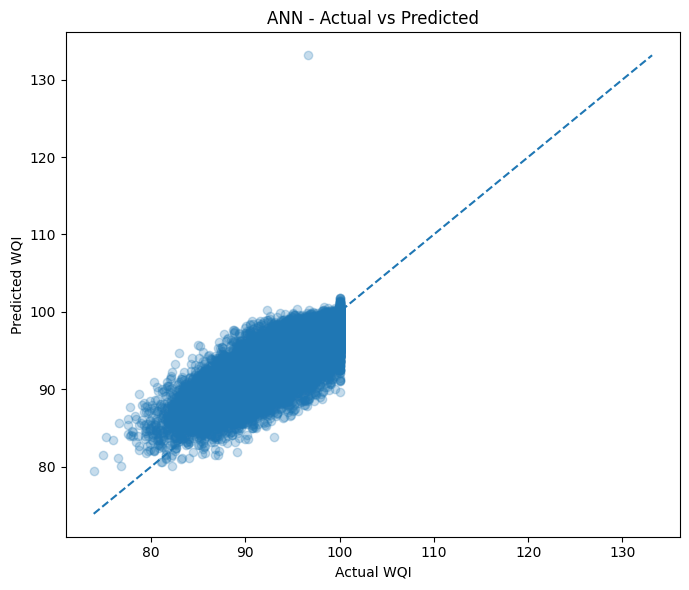

In [23]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test_final, test_pred, alpha=0.25)
mn = min(y_test_final.min(), test_pred.min())
mx = max(y_test_final.max(), test_pred.max())
plt.plot([mn, mx], [mn, mx], linestyle="--")
plt.xlabel("Actual WQI")
plt.ylabel("Predicted WQI")
plt.title(best_model_name + " - Actual vs Predicted")
plt.tight_layout()
plt.show()

#**20- Feature importance**

In [24]:
final_inner = final_model.named_steps["model"]

if hasattr(final_inner, "feature_importances_"):
    imp = pd.Series(
        final_inner.feature_importances_,
        index=X_train_full.columns
    ).sort_values(ascending=False)

    display(imp.to_frame("importance"))

    plt.figure(figsize=(8, 4))
    imp.sort_values().plot(kind="barh")
    plt.tight_layout()
    plt.show()

elif hasattr(final_inner, "coef_"):
    coef = pd.Series(
        np.ravel(final_inner.coef_),
        index=X_train_full.columns
    ).sort_values(key=np.abs, ascending=False)

    display(coef.to_frame("coefficient"))
else:
    print("No direct feature importance available for this model.")

No direct feature importance available for this model.


#**21- Conclusion**

The water-quality models and feature sets were evaluated using 5-fold Group Cross-Validation, with the test set kept untouched during model and feature selection.

The four currently available Aquora water-quality sensors are:
**pH + TDS + Turbidity + Temperature**.

The feature-study experiment showed that additional water-quality variables available in the dataset can improve WQI estimation compared with the four-sensor baseline. This directly addresses the supervisor's requirement to investigate whether the current parameters are sufficient or whether additional parameters are useful.

However, the present hardware only provides the four sensors listed above. Therefore, the **final practical model is selected from the 10 candidate regression models using only these four sensors and 5-fold Group CV**. The broader all-parameter result is reported as a research benchmark, not as the current deployable configuration.

**Current practical contribution:** an ML-based estimator of the dataset's `Water_Quality_Index` using measurements that are actually available in the Aquora water-quality subsystem.

**Context and Future Work:** Additional water-quality parameters that improve the CV results are candidates for future sensor expansion. In future work, the system can investigate adding such parameters, together with validation using independent water-quality/contamination measurements and real sensor data. The current model should be interpreted as estimating the dataset's existing WQI, not as independently proving contamination.


In [25]:
print("Selected practical model:", best_model_name)
print("Selected practical feature set:", best_feature_set_name)
print("Selected features:", best_features)
print("Practical CV R2:", round(float(best_practical_row["CV_R2"]), 4))
print("Practical CV MAE:", round(float(best_practical_row["CV_MAE"]), 4))
print("Practical CV RMSE:", round(float(best_practical_row["CV_RMSE"]), 4))
print("Test R2:", round(float(final_test["Test_R2"].iloc[0]), 4))
print("Test MAE:", round(float(final_test["Test_MAE"].iloc[0]), 4))
print("Test RMSE:", round(float(final_test["Test_RMSE"].iloc[0]), 4))

print("\nResearch benchmark feature set:", research_best_feature_set)
print("Research benchmark CV R2:", round(research_best_cv_r2, 4))

print("\nFuture work: investigate whether additional water-quality sensing can be added later if the demonstrated CV improvement justifies sensor expansion.")


Selected model: ANN
Selected feature set: All water quality
CV R2: 0.6755
Test R2: 0.6655
Test MAE: 2.1769
Test RMSE: 2.7459

Selected features:
['pH', 'Turbidity_NTU', 'TDS_mg_L', 'Temperature_C', 'Dissolved_Oxygen_mg_L', 'Conductivity_umhos_cm', 'BOD_mg_L', 'Nitrate_Nitrite_mg_L', 'Fecal_Coliform_MPN_100ml', 'Total_Coliform_MPN_100ml']

Best 4-sensor screening result:


,Feature_Set,Model,CV_MAE,CV_RMSE,CV_R2,CV_R2_STD
17,4 sensors,LightGBM,2.462193,3.106648,0.580112,0.004633



Water-quality feature screening:


,Feature_Set,Mean_CV_R2,Best_CV_R2,Mean_CV_RMSE,Mean_CV_MAE,R2_Difference_vs_4
0,All water quality,0.672823,0.673144,2.742315,2.157080,0.092865
1,4 + DO,0.619310,0.619398,2.958115,2.334923,0.039353
2,4 + Conductivity,0.613370,0.613587,2.981074,2.357619,0.033412
3,4 + BOD,0.594798,0.594917,3.051830,2.413428,0.014840
4,4 + Nitrate,0.593042,0.593554,3.058451,2.419822,0.013084
5,4 + interactions,0.580728,0.581357,3.104383,2.459992,0.000770
6,4 sensors,0.579958,0.580112,3.107227,2.461687,0.000000
7,4 + Fecal Coliform,0.579875,0.580062,3.107530,2.462008,-0.000082
8,4 + Total Coliform,0.579683,0.579789,3.108248,2.462963,-0.000275



Future work: if extra water-quality parameters provide a substantial gain, investigate whether additional sensing can be added later.
